In [ ]:
# Load data, prepare delta target

import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/kathmandu_features.csv")
df["datetime_utc"] = pd.to_datetime(df["datetime_utc"])
df = df.sort_values("datetime_utc").reset_index(drop=True)

horizon = 24   # changed to 1, 3, 6, 12, 24 for required prediction horizon
target_column = f"target_pm25_next_{horizon}h"
target_columns = [c for c in df.columns if c.startswith("target_")]
feature_columns = [c for c in df.columns if c not in ["datetime_utc"] + target_columns]

current_pm25 = df["pm25"]
y_absolute = df[target_column]
y_delta = y_absolute - current_pm25

# Drop rows where the delta target is NaN 
valid_mask = ~y_delta.isna()
X = df.loc[valid_mask, feature_columns].reset_index(drop=True)
y_delta_valid = y_delta[valid_mask].reset_index(drop=True)
y_absolute_valid = y_absolute[valid_mask].reset_index(drop=True)
current_pm25_valid = current_pm25[valid_mask].reset_index(drop=True)
dates_valid = df.loc[valid_mask, "datetime_utc"].reset_index(drop=True)

print(f"Rows after dropping missing target: {len(X)} (from {len(df)})")
print(f"Features: {len(feature_columns)}")

# Hold-out: keeping the last period aside, used once at the end
test_start = pd.Timestamp("2026-08-01")
dev = (dates_valid < test_start - pd.Timedelta(hours=horizon)).values
hold = (dates_valid >= test_start).values

X_full, y_delta_full = X, y_delta_valid  

X_hold = X[hold].reset_index(drop=True)
y_abs_hold = y_absolute_valid[hold].reset_index(drop=True)
pm25_hold = current_pm25_valid[hold].reset_index(drop=True)
dates_hold = dates_valid[hold].reset_index(drop=True)

X = X[dev].reset_index(drop=True)
y_delta_valid = y_delta_valid[dev].reset_index(drop=True)
y_absolute_valid = y_absolute_valid[dev].reset_index(drop=True)
current_pm25_valid = current_pm25_valid[dev].reset_index(drop=True)
dates_valid = dates_valid[dev].reset_index(drop=True)

print(f"Development: {len(X)} rows, Hold-out: {len(X_hold)} rows "
      f"({dates_hold.min().date()} to {dates_hold.max().date()})")

Rows after dropping missing target: 7796 (from 8343)
Features: 32
Development: 6470 rows, Hold-out: 1302 rows (2026-08-01 to 2026-09-02)


In [50]:
# Define the search space and run RandomizedSearchCV

param_distributions = {
    "n_estimators": [50, 100, 150, 200, 300],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.5, 1, 1.5, 2],
}

tscv = TimeSeriesSplit(n_splits=5, gap=2 * horizon)

base_model = xgb.XGBRegressor(random_state=42, n_jobs=-1)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

search.fit(X, y_delta_valid)

print("Best parameters found:")
print(search.best_params_)
print(f"\nBest CV RMSE (on delta target): {-search.best_score_:.3f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters found:
{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.6}

Best CV RMSE (on delta target): 28.056


In [51]:
# Evaluate the tuned model on the same folds, reconstructed to absolute PM2.5

tuned_results = []
tuned_predictions = []

best_params = search.best_params_

for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_delta_train = y_delta_valid.iloc[train_idx]
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]
    dates_test = dates_valid.iloc[test_idx]

    model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
    model.fit(X_train, y_delta_train)

    predicted_delta = model.predict(X_test)
    predicted_absolute = current_pm25_test.values + predicted_delta

    valid_mask_fold = ~np.isnan(predicted_absolute)

    rmse = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold]))
    mae = mean_absolute_error(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold])
    r2 = r2_score(y_absolute_test[valid_mask_fold], predicted_absolute[valid_mask_fold])

    tuned_results.append({"fold": fold_num, "rmse_tuned": rmse, "mae_tuned": mae, "r2_tuned": r2})
    tuned_predictions.append({
        "fold": fold_num, "dates": dates_test[valid_mask_fold],
        "station": np.where(X_test["station_teku"].astype(bool), "Teku", "Mid Baneshwor")[valid_mask_fold],
        "y_actual": y_absolute_test[valid_mask_fold], "y_pred": predicted_absolute[valid_mask_fold],
    })

    print(f"Fold {fold_num} ({dates_test.min().date()} to {dates_test.max().date()}): "
          f"RMSE={rmse:.2f} MAE={mae:.2f} R2={r2:.3f}")

tuned_df = pd.DataFrame(tuned_results)

Fold 1 (2025-12-17 to 2026-01-10): RMSE=25.85 MAE=17.86 R2=0.450
Fold 2 (2026-01-10 to 2026-03-09): RMSE=31.77 MAE=22.36 R2=0.463
Fold 3 (2026-03-09 to 2026-04-11): RMSE=28.85 MAE=21.64 R2=-0.263
Fold 4 (2026-04-11 to 2026-06-22): RMSE=40.45 MAE=24.79 R2=0.263
Fold 5 (2026-06-22 to 2026-07-30): RMSE=13.37 MAE=10.51 R2=0.189


In [52]:
# Final, one-time evaluation on the hold-out (NOT USED FOR TUNING)

holdout_model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
holdout_model.fit(X, y_delta_valid)   # development data only
pred_hold = pm25_hold.values + holdout_model.predict(X_hold)

rmse_hold = np.sqrt(mean_squared_error(y_abs_hold, pred_hold))
mae_hold = mean_absolute_error(y_abs_hold, pred_hold)
r2_hold = r2_score(y_abs_hold, pred_hold)
rmse_hold_persist = np.sqrt(mean_squared_error(y_abs_hold, pm25_hold))
skill_hold = 1 - rmse_hold / rmse_hold_persist

print(f"Hold-out {dates_hold.min().date()} to {dates_hold.max().date()}")
print(f"Tuned XGBoost: RMSE={rmse_hold:.2f}  MAE={mae_hold:.2f}  R2={r2_hold:.3f}")
print(f"Persistence  : RMSE={rmse_hold_persist:.2f}")
print(f"Skill vs persistence: {skill_hold * 100:+.1f}%")

Hold-out 2026-08-01 to 2026-09-02
Tuned XGBoost: RMSE=11.31  MAE=8.62  R2=-0.074
Persistence  : RMSE=11.06
Skill vs persistence: -2.3%


In [53]:
# Compare tuned model against the untuned XGBoost and persistence

# Persistence, recomputed on the same valid-row set
persist_results = []
for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]
    valid_mask_p = ~current_pm25_test.isna()
    rmse_p = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_p], current_pm25_test[valid_mask_p]))
    r2_p = r2_score(y_absolute_test[valid_mask_p], current_pm25_test[valid_mask_p])
    persist_results.append({"fold": fold_num, "rmse_persist": rmse_p, "r2_persist": r2_p})
persist_df = pd.DataFrame(persist_results)

# Untuned XGBoost for comparison
untuned_results = []
for fold_num, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_delta_train = y_delta_valid.iloc[train_idx]
    y_absolute_test = y_absolute_valid.iloc[test_idx]
    current_pm25_test = current_pm25_valid.iloc[test_idx]

    untuned_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=-1,)
    untuned_model.fit(X_train, y_delta_train)
    pred_delta = untuned_model.predict(X_test)
    pred_absolute = current_pm25_test.values + pred_delta

    valid_mask_u = ~np.isnan(pred_absolute)
    rmse_u = np.sqrt(mean_squared_error(y_absolute_test[valid_mask_u], pred_absolute[valid_mask_u]))
    r2_u = r2_score(y_absolute_test[valid_mask_u], pred_absolute[valid_mask_u])
    untuned_results.append({"fold": fold_num, "rmse_untuned": rmse_u, "r2_untuned": r2_u})
untuned_df = pd.DataFrame(untuned_results)

final_comparison = tuned_df.merge(untuned_df, on="fold").merge(persist_df, on="fold")

print(final_comparison[["fold", "rmse_tuned", "rmse_untuned", "rmse_persist"]].to_string(index=False))
print()
print(final_comparison[["fold", "r2_tuned", "r2_untuned", "r2_persist"]].to_string(index=False))

print()
print("=== AVERAGES ===")
print(f"Tuned XGBoost   : RMSE={final_comparison['rmse_tuned'].mean():.2f}  R2={final_comparison['r2_tuned'].mean():.3f}")
print(f"Untuned XGBoost : RMSE={final_comparison['rmse_untuned'].mean():.2f}  R2={final_comparison['r2_untuned'].mean():.3f}")
print(f"Persistence     : RMSE={final_comparison['rmse_persist'].mean():.2f}  R2={final_comparison['r2_persist'].mean():.3f}")

improvement_vs_persist = (1 - final_comparison['rmse_tuned'].mean() / final_comparison['rmse_persist'].mean()) * 100
improvement_vs_untuned = (1 - final_comparison['rmse_tuned'].mean() / final_comparison['rmse_untuned'].mean()) * 100
print(f"\nTuned model improvement over persistence: {improvement_vs_persist:.1f}%")
print(f"Tuned model improvement over untuned XGBoost: {improvement_vs_untuned:.1f}%")

 fold  rmse_tuned  rmse_untuned  rmse_persist
    1   25.849387     26.149174     29.306321
    2   31.766116     31.674122     34.940678
    3   28.845273     30.611629     28.874381
    4   40.447964     41.537894     47.017431
    5   13.370249     15.994820     12.165223

 fold  r2_tuned  r2_untuned  r2_persist
    1  0.450488    0.437668    0.293684
    2  0.463151    0.466256    0.350489
    3 -0.262898   -0.422302   -0.265448
    4  0.263223    0.222980    0.004455
    5  0.188635   -0.161171    0.328296

=== AVERAGES ===
Tuned XGBoost   : RMSE=28.06  R2=0.221
Untuned XGBoost : RMSE=29.19  R2=0.109
Persistence     : RMSE=30.46  R2=0.142

Tuned model improvement over persistence: 7.9%
Tuned model improvement over untuned XGBoost: 3.9%


In [54]:
# Unseen-data predictions from the CV folds (development period)
cv_df = pd.concat([
    pd.DataFrame({
        "fold": f["fold"],
        "station": f["station"],
        "time": f["dates"].values,
        "actual": f["y_actual"].values,
        "predicted": np.round(f["y_pred"], 1),
    })
    for f in tuned_predictions
], ignore_index=True)
cv_df["error"] = (cv_df["predicted"] - cv_df["actual"]).round(1)

print(cv_df.head(20).to_string(index=False))
cv_df.to_csv(f"../models/cv_predictions_{horizon}h.csv", index=False)

 fold       station                time  actual  predicted  error
    1 Mid Baneshwor 2025-12-17 15:15:00   175.0      131.9  -43.1
    1 Mid Baneshwor 2025-12-17 16:15:00   163.0      132.2  -30.8
    1          Teku 2025-12-17 16:15:00   243.0      123.3 -119.7
    1 Mid Baneshwor 2025-12-17 17:15:00   140.0      116.6  -23.4
    1          Teku 2025-12-17 17:15:00   165.0       99.6  -65.4
    1 Mid Baneshwor 2025-12-17 18:15:00   139.0       97.1  -41.9
    1          Teku 2025-12-17 18:15:00   113.0       85.9  -27.1
    1 Mid Baneshwor 2025-12-17 19:15:00   136.0       94.7  -41.3
    1          Teku 2025-12-17 19:15:00    97.7       82.3  -15.4
    1 Mid Baneshwor 2025-12-17 20:15:00   112.0       86.1  -25.9
    1          Teku 2025-12-17 20:15:00    75.0       65.6   -9.4
    1 Mid Baneshwor 2025-12-17 21:15:00   111.0       77.1  -33.9
    1          Teku 2025-12-17 21:15:00    76.2       75.7   -0.5
    1          Teku 2025-12-17 22:15:00   135.0       66.6  -68.4
    1 Mid 

In [55]:
# Unseen-data predictions on the hold-out period (August)
hold_df = pd.DataFrame({
    "time": dates_hold,
    "station": np.where(X_hold["station_teku"].astype(bool), "Teku", "Mid Baneshwor"),
    "current_pm25": pm25_hold.values,
    "actual": y_abs_hold.values,
    "predicted": pred_hold.round(1),
})
hold_df["error"] = (hold_df["predicted"] - hold_df["actual"]).round(1)

print(hold_df.head(20).to_string(index=False))
hold_df.to_csv(f"../models/holdout_predictions_{horizon}h.csv", index=False)

               time       station  current_pm25  actual  predicted  error
2026-08-01 00:15:00 Mid Baneshwor          24.8    16.3       27.1   10.8
2026-08-01 01:15:00 Mid Baneshwor          28.1    16.7       30.4   13.7
2026-08-01 02:15:00 Mid Baneshwor          34.7    17.8       37.0   19.2
2026-08-01 03:15:00 Mid Baneshwor          24.0    19.4       26.5    7.1
2026-08-01 04:15:00 Mid Baneshwor          20.2    26.4       22.7   -3.7
2026-08-01 05:15:00 Mid Baneshwor          22.3    26.6       25.7   -0.9
2026-08-01 06:15:00 Mid Baneshwor          18.5    18.5       21.3    2.8
2026-08-01 07:15:00 Mid Baneshwor          19.8    11.6       22.3   10.7
2026-08-01 08:15:00 Mid Baneshwor          20.8    32.2       23.3   -8.9
2026-08-01 09:15:00 Mid Baneshwor          12.6    20.1       15.1   -5.0
2026-08-01 10:15:00 Mid Baneshwor          11.4    20.1       13.7   -6.4
2026-08-01 11:15:00 Mid Baneshwor          25.5    23.6       27.8    4.2
2026-08-01 12:15:00 Mid Baneshwor     

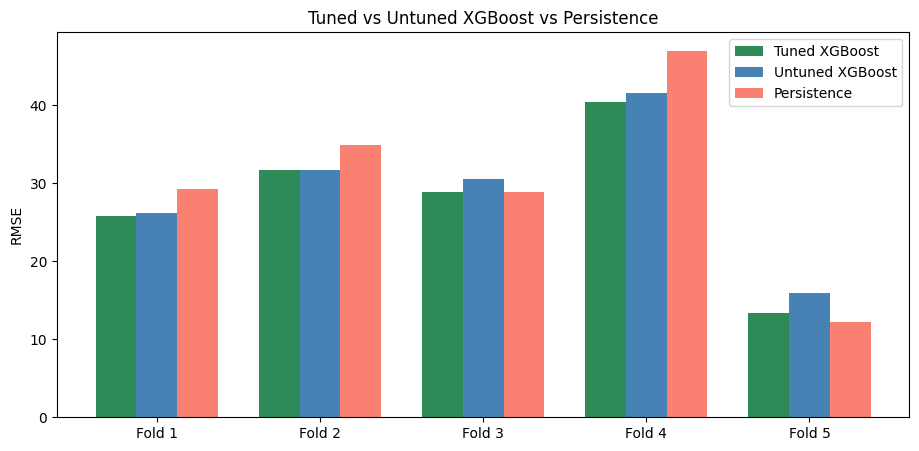

In [56]:
# RMSE per fold (all three)

x = np.arange(5)
width = 0.25

plt.figure(figsize=(11, 5))
plt.bar(x - width, final_comparison["rmse_tuned"], width, label="Tuned XGBoost", color="seagreen")
plt.bar(x, final_comparison["rmse_untuned"], width, label="Untuned XGBoost", color="steelblue")
plt.bar(x + width, final_comparison["rmse_persist"], width, label="Persistence", color="salmon")
plt.xticks(x, [f"Fold {i+1}" for i in range(5)])
plt.ylabel("RMSE")
plt.title("Tuned vs Untuned XGBoost vs Persistence")
plt.legend()
plt.show()

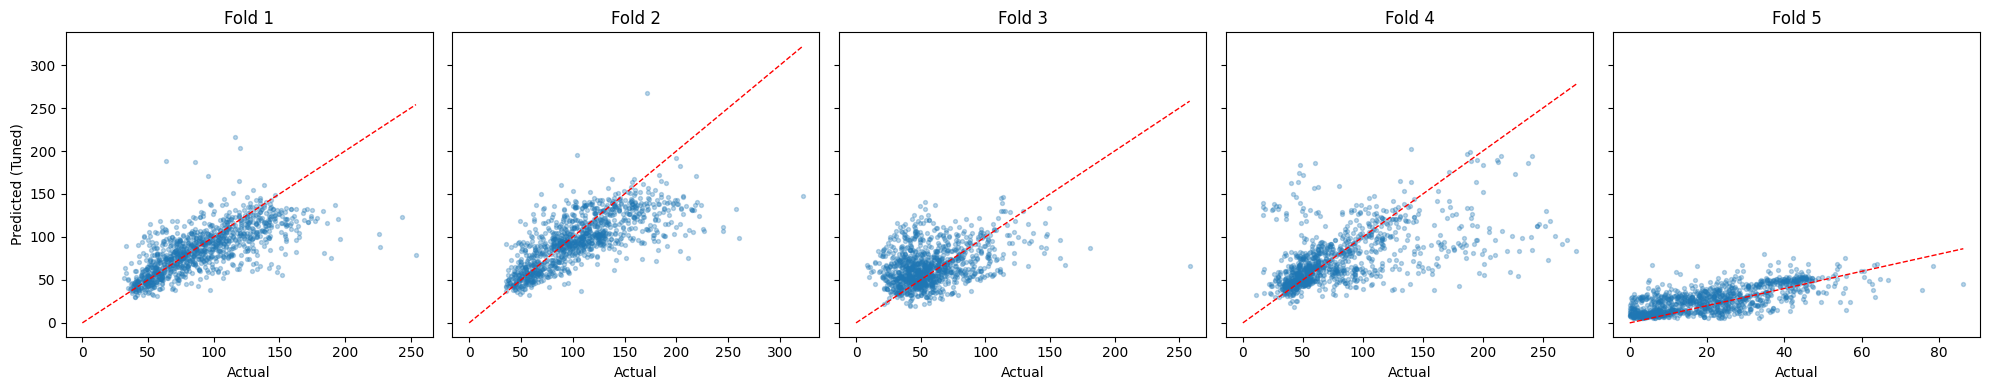

In [57]:
# Predicted vs actual, per fold (tuned model)

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for i, fold_data in enumerate(tuned_predictions):
    ax = axes[i]
    ax.scatter(fold_data["y_actual"], fold_data["y_pred"], alpha=0.3, s=8)
    lims = [0, max(fold_data["y_actual"].max(), fold_data["y_pred"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(f"Fold {fold_data['fold']}")
    ax.set_xlabel("Actual")
    if i == 0:
        ax.set_ylabel("Predicted (Tuned)")

plt.tight_layout()
plt.show()

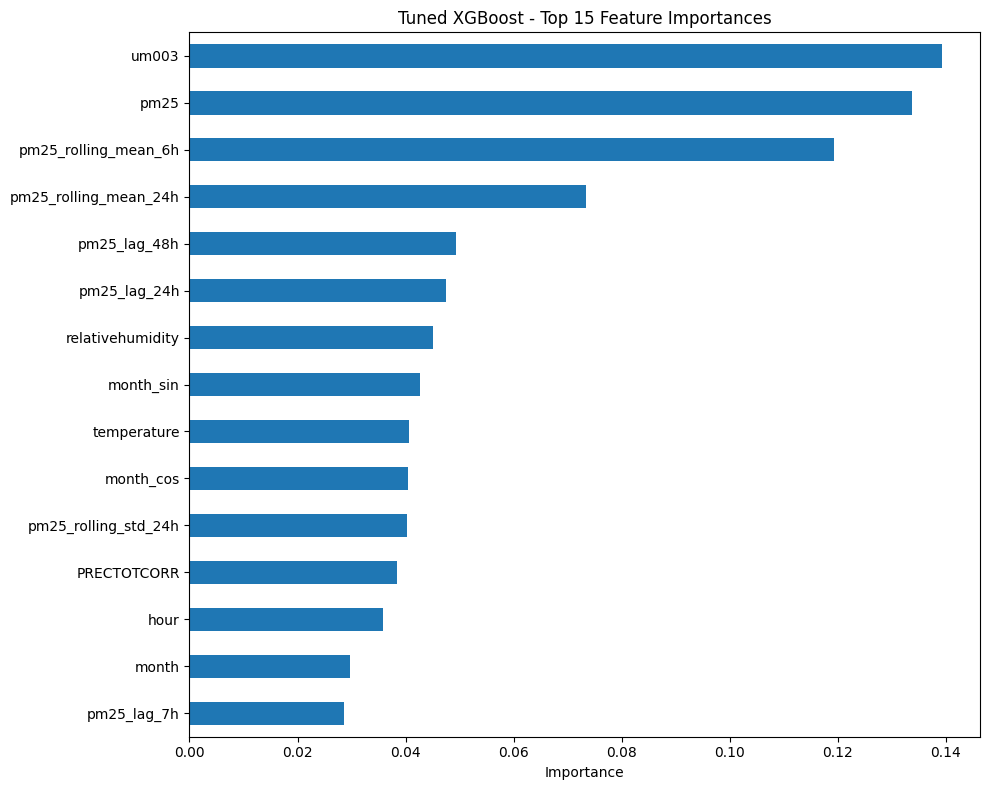

um003                    0.139356
pm25                     0.133737
pm25_rolling_mean_6h     0.119273
pm25_rolling_mean_24h    0.073378
pm25_lag_48h             0.049419
pm25_lag_24h             0.047423
relativehumidity         0.045059
month_sin                0.042688
temperature              0.040704
month_cos                0.040390
pm25_rolling_std_24h     0.040212
PRECTOTCORR              0.038499
hour                     0.035778
month                    0.029776
pm25_lag_7h              0.028536
dtype: float32


In [58]:
# Feature importance (tuned model, trained on full data)

final_tuned_model = xgb.XGBRegressor(random_state=42, n_jobs=-1, **best_params)
#final_tuned_model.fit(X, y_delta_valid)
final_tuned_model.fit(X_full, y_delta_full)       #new

importances_tuned = pd.Series(final_tuned_model.feature_importances_, index=feature_columns).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importances_tuned.head(15).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Tuned XGBoost - Top 15 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances_tuned.head(15))

In [59]:
# Save the tuned model and results

import os
import joblib
import json

os.makedirs("../models", exist_ok=True)

joblib.dump(final_tuned_model, f"../models/xgboost_tuned_final_{horizon}h.pkl")

tuning_summary = {
    "horizon": horizon,
    "model": "XGBoost (tuned, delta target)",
    "validation": "Dev period (before 2026-08-01): TimeSeriesSplit (5 folds), RandomizedSearchCV (n_iter=50); hold-out: 2026-08-01 onward",
    "best_params": best_params,
    "tuned_avg_rmse": final_comparison["rmse_tuned"].mean(),
    "tuned_avg_r2": final_comparison["r2_tuned"].mean(),
    "untuned_avg_rmse": final_comparison["rmse_untuned"].mean(),
    "untuned_avg_r2": final_comparison["r2_untuned"].mean(),
    "persistence_avg_rmse": final_comparison["rmse_persist"].mean(),
    "persistence_avg_r2": final_comparison["r2_persist"].mean(),
    "holdout_rmse": rmse_hold,
    "holdout_mae": mae_hold,
    "holdout_r2": r2_hold,
    "holdout_persistence_rmse": rmse_hold_persist,
    "holdout_skill": skill_hold,
}

with open(f"../models/tuning_results_{horizon}h.json", "w") as f:
        json.dump(tuning_summary, f, indent=2, default=str)

print(f"Saved tuned model to ../models/xgboost_tuned_final_{horizon}h.pkl")
print(f"Saved results to ../models/tuning_results_{horizon}h.json")
print(tuning_summary)

Saved tuned model to ../models/xgboost_tuned_final_24h.pkl
Saved results to ../models/tuning_results_24h.json
{'horizon': 24, 'model': 'XGBoost (tuned, delta target)', 'validation': 'Dev period (before 2026-08-01): TimeSeriesSplit (5 folds), RandomizedSearchCV (n_iter=50); hold-out: 2026-08-01 onward', 'best_params': {'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.6}, 'tuned_avg_rmse': np.float64(28.055797797910042), 'tuned_avg_r2': np.float64(0.2205195986022816), 'untuned_avg_rmse': np.float64(29.19352778515316), 'untuned_avg_r2': np.float64(0.10868625469863795), 'persistence_avg_rmse': np.float64(30.46080663062914), 'persistence_avg_r2': np.float64(0.14229519565263152), 'holdout_rmse': np.float64(11.31347001242388), 'holdout_mae': 8.622965409233595, 'holdout_r2': -0.07381691956351077, 'holdout_persistence_rmse': np.float64(11.061843969803986), 'holdout_skill': np.float64(-0.

 horizon_h  cv_rmse  cv_persist_rmse  cv_skill_%  holdout_rmse  holdout_persist_rmse  holdout_skill_%
         1    14.51            16.69       13.06          6.56                  7.05             6.92
         3    21.99            31.17       29.48          9.53                 12.01            20.60
         6    25.22            41.26       38.86          9.76                 15.02            35.07
        12    27.07            35.01       22.67         12.14                 12.53             3.10
        24    28.06            30.46        7.90         11.31                 11.06            -2.27


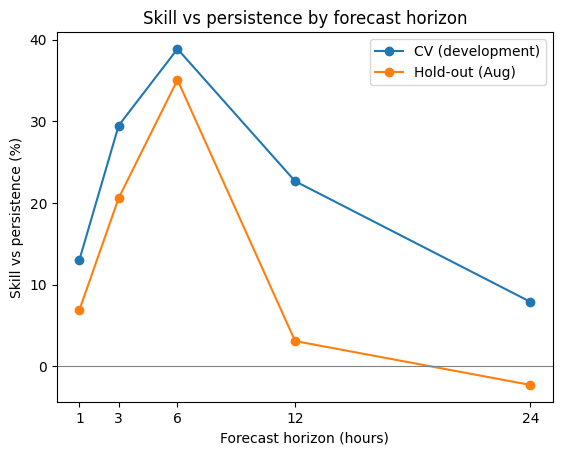

In [60]:
# Summary across all horizons (run only after all five runs are done)
import json
rows = []
for h_ in [1, 3, 6, 12, 24]:
    r = json.load(open(f"../models/tuning_results_{h_}h.json"))
    rows.append({
        "horizon_h": h_,
        "cv_rmse": r["tuned_avg_rmse"],
        "cv_persist_rmse": r["persistence_avg_rmse"],
        "cv_skill_%": (1 - r["tuned_avg_rmse"] / r["persistence_avg_rmse"]) * 100,
        "holdout_rmse": r["holdout_rmse"],
        "holdout_persist_rmse": r["holdout_persistence_rmse"],
        "holdout_skill_%": r["holdout_skill"] * 100,
    })
horizon_table = pd.DataFrame(rows).round(2)
print(horizon_table.to_string(index=False))
horizon_table.to_csv("../models/horizon_results.csv", index=False)

plt.plot(horizon_table["horizon_h"], horizon_table["cv_skill_%"], marker="o", label="CV (development)")
plt.plot(horizon_table["horizon_h"], horizon_table["holdout_skill_%"], marker="o", label="Hold-out (Aug)")
plt.axhline(0, color="grey", linewidth=0.8)
plt.xticks([1, 3, 6, 12, 24])
plt.xlabel("Forecast horizon (hours)")
plt.ylabel("Skill vs persistence (%)")
plt.title("Skill vs persistence by forecast horizon")
plt.legend()
plt.show()